In [36]:
import pandas as pd 

# Predicting Traffic Slowdowns at Known Maritime Chokepoints

## Chokepoint Day
### The dataset is chronological, so a unit of observation is a chokepoint day

For dataset $D$, observation $i$, calendar date $t$ and observed chokepoint-date combinations $\Omega$ 

$$D = \{(i, t, \mathbb{Y}_{i, t}): (i, t) \in \Omega\} $$

*Multiple chokepoints are observed over time, but importantly each observation is not independent. They have to be considered as part of a time series, and all sampling, data splitting, predicting, and validating must be designed specifically for temporal data to avoid data leakage.*


In [55]:
daily_chkpnt = pd.read_csv("Daily_Chokepoints_Data.csv")
disruption_events = pd.read_csv("pw_disruptions_db.csv")


/tmp/ipykernel_1854/3024079888.py:12: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


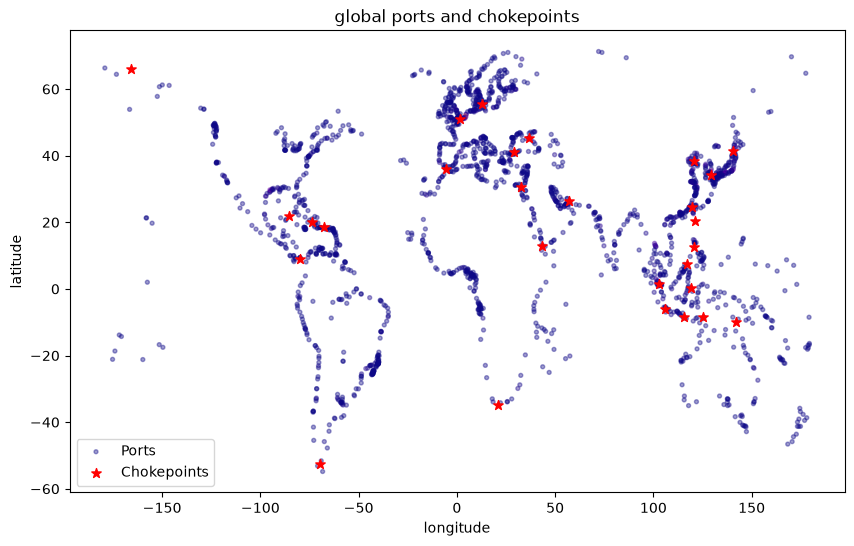

In [56]:
ports = pd.read_csv("Ports.csv")
import matplotlib.pyplot as plt 

chokepoints = pd.read_csv("PortWatch_chokepoints_database.csv")

plt.figure(figsize=(10, 6))
plt.scatter(x=ports["lon"], y=ports["lat"], c=ports["vessel_count_tanker"], cmap='plasma', alpha=0.4, s=8, label="Ports")
plt.title("global ports and chokepoints")
plt.xlabel("longitude")
plt.ylabel("latitude")

plt.scatter(
    chokepoints["lon"], 
    chokepoints["lat"],
    c="red",
    cmap="tab20",
    marker="*",
    s=50,
    label="Chokepoints"
)
plt.legend()

plt.show()

In [57]:

disruption_events.head()

,eventid,eventtype,eventname,htmlname,htmldescription,alertlevel,country,fromdate,year,todate,...,lat,long,editdate,affectedports,n_affectedports,affectedpopulation,pageid,ObjectId,Shape__Area,Shape__Length
0,1000552,TC,IDAI-19,Tropical Cyclone IDAI-19,"Red Tropical Cyclone IDAI-19 in Mozambique, Zi...",RED,Mozambique,3/9/2019 6:00:00 AM,2019,3/15/2019 12:00:00 AM,...,-19.6000,34.800,9/10/2023 1:47:19 AM,port137,1,1.9 million in Category 1 or higher,3aa1164d42fb42e99f8ed581b6ecd4d1,1,3.500007e+11,3.223230e+06
1,1000227,FL,Flood in Mozambique,Flood in Mozambique,Red Flood in Mozambique from: 09 Mar 2019 00 t...,RED,Mozambique,3/9/2019 12:00:00 AM,2019,3/29/2019 12:00:00 AM,...,-15.1780,36.432,9/10/2023 1:49:27 AM,port137; port784; port896,3,NaN,c2ad419a75d24ec28ae55a0728a0eb79,2,6.425900e+11,5.359811e+06
2,1000559,TC,KENNETH-19,Tropical Cyclone KENNETH-19,"Red Tropical Cyclone KENNETH-19 in , Mozambiqu...",RED,Mozambique; Comoros,4/23/2019 12:00:00 AM,2019,4/25/2019 6:00:00 PM,...,-12.3000,40.100,9/10/2023 1:53:22 AM,port896; port769,2,260 thousand in Category 1 or higher,74c5908f37dd496caedc335fc2bcf6e1,3,2.263530e+11,2.574508e+06
3,1000561,TC,FANI-19,Tropical Cyclone FANI-19,"Red Tropical Cyclone FANI-19 in , India, Bangl...",RED,India,4/27/2019 12:00:00 AM,2019,5/3/2019 12:00:00 PM,...,21.3000,86.200,9/10/2023 1:54:47 AM,port290; port883,2,1.8 million in Category 1 or higher,7a4e3ee5892f497a996870d3e0e6f414,4,5.600202e+11,4.851356e+06
4,1178759,EQ,"Earthquake in Eastern New Guinea Reg., P.N.G.","Earthquake in Eastern New Guinea Reg., P.N.G.",Red M 7.2 Earthquake in Eastern New Guinea Reg...,RED,Papua New Guinea,5/6/2019 9:19:35 PM,2019,5/6/2019 9:19:35 PM,...,-6.9767,146.440,9/10/2023 1:55:14 AM,port624,1,NaN,98299d6738574f2ea18e46e19f71327e,5,3.206445e+10,6.348622e+05


## Checking for Duplicate Observations

### Number of Unique Observations

For $N$ rows in the dataset, $K$ unique chokepoints and set $T$ of unique dates a complete panel should contain

$$ 
N_{\text{unique}} = K|T|
$$ 

Each chokepoint should also have one observation for each date in $T$. We verify

- $\forall (i, t) \in D: \sum_{i, t \in D} \mathbb{I}\left((i_k, t_k) = (i, t)\right) = 1$
- $|T| = T_{\text{max}} - T_{min}$
- No missing values for each feature

### Missingness 

Let $M_j$ be the number of missing entries for feature $j$, then

$$ r_j = \frac{M_j}{N} $$

Analysis uses available daily observations for selected chokepoints over the time period, therefore this is a longitudinal observation panel, not a simpe random sample. 

Inferences are conditional on the coverage, measurement process and time period of available data. 

In [40]:
daily_chkpnt["date"] = pd.to_datetime(
    daily_chkpnt["date"], errors="coerce"
)

print("daily data shape: ", daily_chkpnt.shape)
print("date range: ", daily_chkpnt["date"].min(), daily_chkpnt["date"].max())

print("Unique chokepoints: ", daily_chkpnt["portid"].nunique())
print("Unique dates: ", daily_chkpnt["date"].nunique())

print("Duplicate chokepoint-date rows: ", daily_chkpnt.duplicated(["portid", "date"]).sum())
print("\nChokepoint Names: ")
print(daily_chkpnt[["portid", "portname"]]
      .drop_duplicates()
      .sort_values("portname")
      .to_string(index=False)
)

print("\nMissing values: ")
print(daily_chkpnt.isna().sum().sort_values(ascending=False).head(15))

daily data shape:  (79744, 21)
date range:  2019-01-01 00:00:00 2026-10-18 00:00:00
Unique chokepoints:  28
Unique dates:  2848
Duplicate chokepoint-date rows:  0

Chokepoint Names: 
      portid             portname
 chokepoint4 Bab el-Mandeb Strait
chokepoint25       Balabac Strait
chokepoint26        Bering Strait
chokepoint17         Bohai Strait
 chokepoint3      Bosporus Strait
 chokepoint7    Cape of Good Hope
 chokepoint9         Dover Strait
 chokepoint8     Gibraltar Strait
chokepoint28         Kerch Strait
chokepoint12         Korea Strait
chokepoint15        Lombok Strait
chokepoint14         Luzon Strait
chokepoint21      Magellan Strait
chokepoint20      Makassar Strait
 chokepoint5       Malacca Strait
chokepoint27       Mindoro Strait
chokepoint24         Mona Passage
chokepoint16         Ombai Strait
chokepoint10       Oresund Strait
 chokepoint2         Panama Canal
 chokepoint6     Strait of Hormuz
 chokepoint1           Suez Canal
chokepoint19         Sunda Strait
c

## Temporal Completeness 

Modeling time series involves using a 1 day lag and a $k$ day rolling window to prevent data leakage. This requires that the samples from the time series are complete and chronological. 

A mean taken from a 7-day window is only valid if days are sequential and each day in the time period is represented. 

In [41]:
expected_days = (
    daily_chkpnt["date"].max() - daily_chkpnt["date"].min()
).days + 1

print("Expected days: ", expected_days)
print("Expected rows: ", expected_days * daily_chkpnt["portid"].nunique())

coverage = daily_chkpnt.groupby("portname").agg(
    first_date=("date", "min"),
    last_date=("date", "max"),
    days_observed=("date", "nunique")
)

print("All dates covered" if coverage[coverage["days_observed"] != expected_days].empty else f"missing {len(coverage[coverage["days_observed"] != expected_days])} days")

Expected days:  2848
Expected rows:  79744
All dates covered


## Descriptive Analysis 

### Mean daily traffic

We calculate the mean $\bar{\mathbb{Y}}_t$ for time period $T$

$$
\bar{\mathbb{Y}}_t = \frac{1}{T_i} \sum_{t=1}^{T_i} \mathbb{Y}_{i, t}
$$

### Sample variance and standard deviation

$$
\sigma_i^2 = \frac{1}{T_i - 1} \sum_{t=1}^{T_i} (\mathbb{Y}_{i, t} - \bar{\mathbb{Y}}_i)^2
$$

$$
\sigma = \sqrt{\sigma_i^2}
$$

### Median 

$$
\widetilde{\mathbb{Y}} = \operatorname{median}\{\:(i,t)\in \Omega\}
$$ 

These statistics are calculated for the entire time series. We will caclulate again for individual chokepoints, time horizons. 

In [42]:
print(daily_chkpnt[["n_total", "n_cargo", "capacity"]].describe())

traffic_summary = daily_chkpnt.groupby("portname").agg(
    mean_traffic=("n_total", "mean"),
    median_traffic=("n_total", "median"),
    std_traffic=("n_total", "std"),
    min_traffic=("n_total", "min"),
    max_traffic=("n_total", "max")
).sort_values("mean_traffic", ascending=False)

print(traffic_summary.to_string())


            n_total       n_cargo      capacity
count  79744.000000  79744.000000  7.974400e+04
mean      70.714850     49.875389  2.107666e+06
std       71.157017     51.801458  2.102331e+06
min        0.000000      0.000000  0.000000e+00
25%       17.000000     12.000000  2.920890e+05
50%       46.000000     32.000000  1.410168e+06
75%       95.000000     66.000000  3.257265e+06
max      472.000000    352.000000  1.632013e+07
                      mean_traffic  median_traffic  std_traffic  min_traffic  max_traffic
portname                                                                                 
Taiwan Strait           243.332865           245.0    37.252838            7          472
Korea Strait            227.948385           230.0    32.217819            1          448
Malacca Strait          199.633076           206.0    33.867433          101          298
Bohai Strait            175.634129           179.0    32.984519            1          459
Dover Strait            166.

## Visualizing raw time series 

- Trend $\mu_{i,t}$: whether typical traffic changes over an observation period. 
- Seasonality $S_{i, t}$: recurring calendar patterns. 
- Short term variability $\epsilon_{i, t}$: Whether individual observations fluctuate substantially. 

$$
\mathbb{Y}_{i, t} = \mu_{i,t} + S_{i, t} + \epsilon_{i, t}
$$

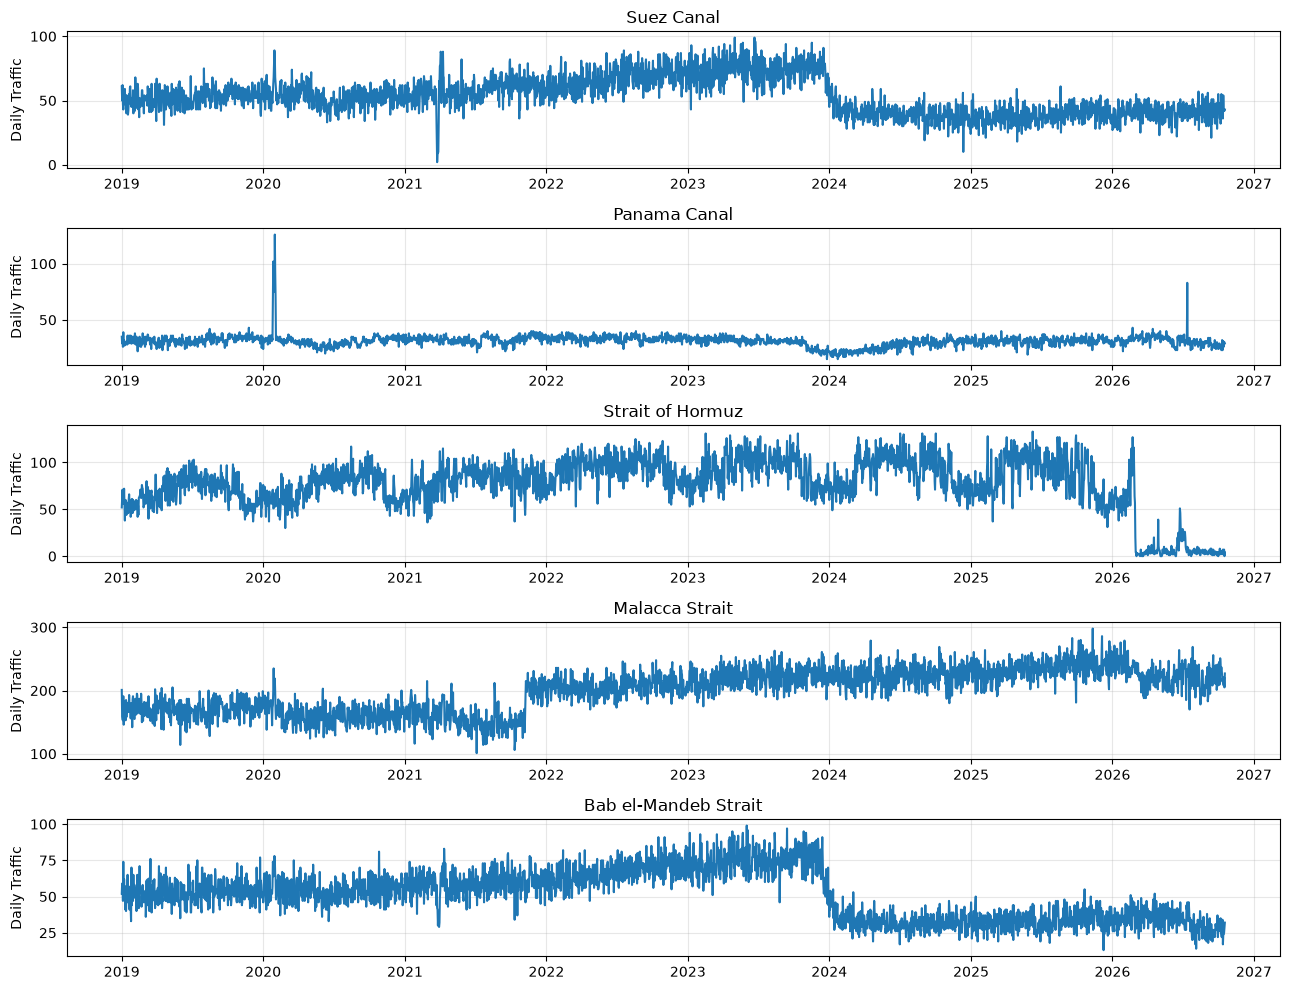

In [43]:
import matplotlib.pyplot as plt

test_ports = [
    "Suez Canal",
    "Panama Canal",
    "Strait of Hormuz",
    "Malacca Strait",
    "Bab el-Mandeb Strait"
]

fig, axes = plt.subplots(len(test_ports), 1, figsize=(13, 10))

for ax, name in zip(axes, test_ports):
    subset = daily_chkpnt[daily_chkpnt["portname"] == name].sort_values("date")

    ax.plot(subset["date"], subset["n_total"])
    ax.set_title(name)
    ax.set_ylabel("Daily Traffic")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Checking Availability and Validity of Disruption Labels

For successful classification, the model needs to be trained on sufficient valid labeled events. For disruption $\xi = \{\text{Chokepoint(s), Dates}\}$ we define an event 

$$
E_{i,t} = 
\begin{cases}
1 &\text{if } (i, t) \in \xi \\
0 &\text{otherwise}
\end{cases}
$$

We map disruption events from ```pw_disruptions_db.csv``` to chokepoints and count how may qualifying events exist in the data. 

In [44]:
for col in ["fromdate", "todate"]:
    disruption_events[col] = pd.to_datetime(disruption_events[col], errors="coerce")

print("Disruption event records:", len(disruption_events))
print("Disruption types: ")
print(disruption_events["eventtype"].value_counts(dropna=False))

print("\nAlert levels: ")
print(disruption_events["alertlevel"].value_counts(dropna=False))

print("\nDisruption event date range: ")
print("Earliest start: ", disruption_events["fromdate"].min())
print("Latest start: ", disruption_events["fromdate"].max())

print("\nMissing dates: ")
print(disruption_events[["fromdate", "todate"]].isna().sum())

print("\nSample event records: ")
print(
    disruption_events[
        ["eventid", "eventtype", "eventname", "fromdate", "todate", "severitytext", "affectedports", "n_affectedports"]
    ].head(10).to_string(index=False)
)

Disruption event records: 132
Disruption types: 
eventtype
TC    72
EQ    32
FL    14
OT     5
DR     4
WF     3
VO     2
Name: count, dtype: int64

Alert levels: 
alertlevel
RED       131
ORANGE      1
Name: count, dtype: int64

Disruption event date range: 
Earliest start:  2018-10-21 00:00:00
Latest start:  2026-08-14 21:58:21

Missing dates: 
fromdate    0
todate      2
dtype: int64

Sample event records: 
 eventid eventtype                                     eventname            fromdate              todate                                                severitytext                                                                                                                                                             affectedports  n_affectedports
 1000552        TC                                       IDAI-19 2019-03-09 06:00:00 2019-03-15 00:00:00 Hurricane/Typhoon > 74 mph (maximum wind speed of 194 km/h)                                                                      

/tmp/ipykernel_1854/1312857180.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  disruption_events[col] = pd.to_datetime(disruption_events[col], errors="coerce")


In [45]:
chokepoint_reference = pd.read_csv("PortWatch_chokepoints_database.csv")

disruption_event_port_ids = set(
    disruption_events["affectedports"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

daily_ids = set(daily_chkpnt["portid"].dropna().astype(str))
reference_ids = set(chokepoint_reference["portid"].dropna().astype(str))

print("\nSample event port IDs: ", sorted(disruption_event_port_ids)[:15])
print("Sample daily IDs: ", sorted(daily_ids)[:15])
print("Sample reference IDs: ", sorted(reference_ids)[:15])

print("\nDisruption event IDs matching daily IDs: ", len(disruption_event_port_ids & daily_ids))
print("Event IDs matching reference IDs: ", len(disruption_event_port_ids & reference_ids))
print("Daily IDs matching reference IDs: ", len(daily_ids & reference_ids))

print("\nReference table IDs and names: ")
print(chokepoint_reference[["portid", "portname"]].head(35).to_string(index=False))


Sample event port IDs:  ['chokepoint1', 'chokepoint2', 'chokepoint4', 'chokepoint6', 'chokepoint7', 'port1023', 'port1025', 'port1028', 'port1029', 'port103', 'port1030', 'port1055', 'port1056', 'port1065', 'port1067']
Sample daily IDs:  ['chokepoint1', 'chokepoint10', 'chokepoint11', 'chokepoint12', 'chokepoint13', 'chokepoint14', 'chokepoint15', 'chokepoint16', 'chokepoint17', 'chokepoint18', 'chokepoint19', 'chokepoint2', 'chokepoint20', 'chokepoint21', 'chokepoint22']
Sample reference IDs:  ['chokepoint1', 'chokepoint10', 'chokepoint11', 'chokepoint12', 'chokepoint13', 'chokepoint14', 'chokepoint15', 'chokepoint16', 'chokepoint17', 'chokepoint18', 'chokepoint19', 'chokepoint2', 'chokepoint20', 'chokepoint21', 'chokepoint22']

Disruption event IDs matching daily IDs:  5
Event IDs matching reference IDs:  5
Daily IDs matching reference IDs:  28

Reference table IDs and names: 
      portid             portname
 chokepoint1           Suez Canal
 chokepoint2         Panama Canal
 chok

In [46]:
disruption_events["affected_id_list"] = (
    disruption_events["affectedports"].fillna("").apply(lambda x: [p.strip() for p in x.split(";") if p.strip()])
)

chokepoint_ids = set(daily_chkpnt["portid"].unique())

def classify_event(ids):
    if not ids:
        return "No affected ports listed" 
    if any(p in chokepoint_ids for p in ids):
        return "Direct chokepoint reference"
    return "Ordinary ports only" 

disruption_events["mapping_type"] = disruption_events["affected_id_list"].apply(classify_event)

print("Event mapping categories: ")
print(disruption_events["mapping_type"].value_counts())

direct = disruption_events[
    disruption_events["mapping_type"] == "Direct chokepoint reference"
].copy()

direct["matched_chokepoints"] = direct["affected_id_list"].apply(
    lambda ids: [
        p for p in ids if p in chokepoint_ids
    ]
)

print("\nEvents directly referencing chokepoints: ")
print(
    direct[
        ["eventid", "eventtype", "eventname", "fromdate", "todate", "matched_chokepoints"]
    ].to_string(index=False)
)

Event mapping categories: 
mapping_type
Ordinary ports only            85
No affected ports listed       44
Direct chokepoint reference     3
Name: count, dtype: int64

Events directly referencing chokepoints: 
 eventid eventtype                 eventname   fromdate              todate                     matched_chokepoints
 1000000        OT          RED SEA TENSIONS 2023-12-16                 NaT [chokepoint4, chokepoint1, chokepoint7]
 1000001        OT RESTRICTIONS PANAMA CANAL 2023-11-03 2024-08-05 04:00:00                           [chokepoint2]
10000004        OT                 HORMUZ-26 2026-03-01                 NaT                           [chokepoint6]


# Modeling Maritime Traffic Slowdowns 

Based on limitations to disruption records, trying to predict disruption based on import export data at ports and chokepoints would be difficult if not impossible. Using the total cargo by volume passing through chokepoints, we can instead model traffic slowdown defined by a significant drop in the amount of cargo traversing a chokepoint in a certain time window. We use the Daily Chokepoints Database, grouped by portid and n_total ships traversing. 

## Feature engineering (X)

For prediction date $t \in T$ and each chokepoint $c \in C$ we define two periods

1. A 28 day historical period from $t-28$ days to $t-8$ days for calculating baseline metrics. 
2. A 7 day recent period for calculating recent traffic average. 

Then let $X = \{x_{c,t} : c = 1 ... 28; t = 1 ... T\}$ be the dataset on which we will predict traffic slowdowns. 

We define the following features 

### One-Day Lag

$$ L_{c, t} = x_{c, t-1} $$

Which captires the traffic of the day immediately before the day of prediction. 

### Rolling 7 Day Mean

$$ 
\mu_{c, t}^{(7)} = \frac{1}{7} \sum_{i=1}^7 x_{c,t-i} 
$$

Which captures recent traffic behavior. 

### Rolling 28 Day Mean and Standard Deviation

$$
\mu_{c,t}^{(28)} = \frac{1}{28} \sum_{i=1}^{28} x_{c,t-i}
$$

Which measures a longer historical window of traffic behavior to establish a baseline. 

$$
\sigma_{c,t}^{(28)} = \sqrt{\frac{1}{27} \sum_{i=1}^{28}(x_{c,t-i} - \mu_{c,t}^{(28)})^2}
$$ 

Which measures the volatility/variability in recent traffic levels. 

## Target Construcion (y)

We use the features calculated from previous 7 and 28 day periods from day $t$ to predict the average traffic over the following 7 days, and we compare this prediction agains the ground truth 7 day average for the forecast period, which we will call $F$.

$$
F_{c,t} = \frac{1}{7} \sum_{i=1}^{7} x_{c,t+i}
$$

Then to define a binary target $y$ we choose a threshold proportion of the previous 28 day baseline average traffic. If the average of the 7 day forecast is below that proportion of the baseline, the sample is labeled 1, representing a significant traffic slowdown event. If it is at or above that proportion of the baseline, the sample is labeled 0, as no significant slowdown has occurred.

We begin with a threshold of 70% of the previous 28 day baseline, and review the panel time series to count how many hits this yields. 

$$
y_{c,t} = 
\begin{cases}
1 &\text{if } F_{c,t} < 0.7\mu_{c,t}^{(28)}\\
0 &\text{if } F_{c,t} \geq 0.7\mu_{c,t}^{(28)} 
\end{cases} 
$$

## Chokepoint Identity 

In addition to the predictive features, we need to represent which chokepoint a particular observed traffic baseline/forecast belongs to. We create a list of 28 Chokepoint Variables $C$, and only the chokepoint variable at the index that matches the chokepoint of the current time series will be labeled 1, with all others labeledc 0. This will allow us to track behavior across each chokepoint, and see how traffic behavior varies at different chokepoints. 

$$
C_i = \begin{cases}
1 &\text{ if observation } x_{c,t} \text{ belongs to chokepoint } i\\
0 &\text{ otherwise }
\end{cases} \text{for } i \gets 1 ... 28 
$$

## Complete Dataset 

The complete dataset now resembles a standard classification dataset with features $X$ and targets $Y$. Importantly, there is essentially one timeseries per chokepoint, and therefore one dataset for each. 

$$
\mathbb{D} = \{(X_{c,t}, Y_{c,t}) \text{ for } c  = 1 ... 28 \in C, \text{ for } t \in T\}
$$

$$
\mathbb{X} = \begin{pmatrix}
X_{1,1}\\
X_{1,2}\\
\vdots\\
X_{1,T}\\
X_{2,1}\\
\vdots\\
X_{2,T}\\
\vdots\\
X_{C,T}
\end{pmatrix}

X_{c, t} = \begin{pmatrix}
L_{c,t}\\
\mu_{c,t}^{(7)}\\
\mu_{c,t}^{(28)}\\
\sigma_{c,t}^{(28)}\\
C=\{C_1, C_2, ..., C_{28}\}

\end{pmatrix}

\mathbb{Y} = \begin{pmatrix}
y_{1,1}\\
y_{1,2}\\
\vdots\\
y_{1,T}\\
y_{2,1}\\
\vdots\\
y_{2,T}\\
\vdots\\
y_{C,T}
\end{pmatrix}
$$


In other words for each of 28 Chokepoints, we record metrics for every day $t \in T$ in the time series starting from day 28 using a Moving Average Window of 28 days, 7 days, and 1 day. For each recorded window looking backwards, we record the corresponding 7 day forecast of the average traffic for the following 7 days, which is the target. This ensures that for a given prediction, no data from after the day $t$ on which the prediction is based is included in the feature vector $X$ which will be used to predict the target $Y$.   





In [47]:
#PIVOTING TO PREDICT A SIGNIFICANT TRAFFIC SLOWDOWN BASED ON PAST DATA#

df = daily_chkpnt.sort_values(["portid", "date"]).copy()

g = df.groupby("portid")["n_total"]

#features for traffic model, *historical* traffic only 
df["lag1"] = g.shift(1)
df["mean_7day"] = g.transform(
    lambda s: s.shift(1).rolling(7).mean()
)

df["mean_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).mean()
)
df["std_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).std()
)

#this will be target, average traffic over the following seven days
df["future_mean_7day"] = g.transform(
    lambda s: s.rolling(7).mean().shift(-7)
)

#mask cases where the mean is <= 0
valid_baseline = df["mean_28day"] > 0

df["slowdown"] = pd.NA
df.loc[valid_baseline, "slowdown"] = (
    df.loc[valid_baseline, "future_mean_7day"] < 0.70 * df.loc[valid_baseline, "mean_28day"]
).astype(int)

features = ["lag1", "mean_7day", "mean_28day", "std_28day"]

model_data = df.dropna(
    subset=features + ["future_mean_7day", "slowdown"]
).copy()

model_data["slowdown"] = model_data["slowdown"].astype(int)

print("Usable observations: ", len(model_data))
print("\nTarget distribution: ")
print(model_data["slowdown"].value_counts())
print("\nTarget proportions: ")
print(model_data["slowdown"].value_counts(normalize=True))

Usable observations:  78244

Target distribution: 
slowdown
0    75975
1     2269
Name: count, dtype: int64

Target proportions: 
slowdown
0    0.971001
1    0.028999
Name: proportion, dtype: float64


## Testing different Moving Window sizes and Forecast Horizons

The exploratory analysis of the dataset showed that using the original pre and post $t$ windows, only 2.8% of 78,244 observations had a positive label indicating a traffic slowdown of more than 30% in the target period. There is a tradeoff to be explored between the size of the windows used to calculate baseline averages, the size of the target forecast period, and the threshold for classifying a change in traffic as a slowdown. Here I explore how the number of positive targets varies with different baseline windows, forecast horizons, and slowdown classification thresholds. 

In [48]:
#2.8% is not much to work with, decided to test differnt baseline time windows/forecast horizons

df2 = daily_chkpnt.sort_values(["portid", "date"]).copy()

g = df2.groupby("portid")["n_total"]

baseline_windows = [2, 8, 14, 28, 56]
forecast_horizons = [1, 4, 7, 14, 28]

thresholds = [0.50, 0.60, 0.70, 0.80]
results = []

for b_days in baseline_windows:
    baseline = g.transform(
        lambda s: s.shift(1).rolling(b_days).mean()
    )

    for horizon in forecast_horizons:
        future_mean = g.transform(
            lambda s: s.rolling(horizon).mean().shift(-horizon)
        )

        valid = baseline.gt(0) & future_mean.notna()

        for threshold in thresholds:
            slowdown = (
                future_mean[valid] < threshold * baseline[valid]
            )

            results.append({
                "baseline_days": b_days, 
                "forecast_days": horizon,
                "threshold": threshold,
                "usable_rows": int(valid.sum()),
                "positive_counts": int(slowdown.sum()),
                "positive_rate": slowdown.mean()
            })

results_df = pd.DataFrame(results)

print(
    results_df.sort_values(
        ["forecast_days", "baseline_days", "threshold"]
    ).to_string(index=False)
)



 baseline_days  forecast_days  threshold  usable_rows  positive_counts  positive_rate
             2              1        0.5        78007             2612       0.033484
             2              1        0.6        78007             4324       0.055431
             2              1        0.7        78007             7433       0.095286
             2              1        0.8        78007            12983       0.166434
             8              1        0.5        78440             3003       0.038284
             8              1        0.6        78440             4482       0.057139
             8              1        0.7        78440             7163       0.091318
             8              1        0.8        78440            12121       0.154526
            14              1        0.5        78524             3213       0.040917
            14              1        0.6        78524             4706       0.059931
            14              1        0.7        78524 

# Train Test Split and Pipeline

## Splitting Time Series into Train and Test sets Chronologically 

Time series data has a meaningful chronological order and therefore cannot be shuffled and split like more standard datasets for regression or classification. Instead, we have to split the data chronologically, such that all Training data is taken from before the cutoff date $T_0$, and all Testing is done on the data from after $T_0$. We include a 7 day gap buffer to ensure that none of the training forecast targets use data from the testing period. 

$$
\text{Train} : t < T_0 - 7 \\
\text{Test} : t \geq T_0 
$$ 

## Standardization

Before fitting a model, we standardize the features using Scikit-Learn's Standard Scaler. The intention of this is to put all numerical features on the same scale. The general formula 

For feature j:
$$
x_{i, j}^* = \frac{x_{i,j} - \bar{x}_j}{s_j} 
$$

## Logistic Regression 

Using logistic regression on the scaled features, the model learns a linear combination of regression coefficients $\beta$ for $p$ features

$$
z_i = \beta_0 + \sum_{j=1}^p \beta_j x_{i,j}^*
$$

### Sigmoid function 

The prediction is converted to a value between 0 and 1 representing a probability by the sigmoid function $\sigma(z)$ 

$$
\sigma(z_i) = \frac{1}{1 + e^{-z}}
$$
$$
P(y_i == 1 | X_i) = \sigma(z_i)
$$

For this classification we start with the default classifcation threshold of 0.5 

$$

\hat{y_i} = 
\begin{cases}
1 : &P(y_i==1|X_i) \geq 0.5\\
0 : &P(y_i==1|X_i) < 0.5
\end{cases}
$$

Where a prediction of 1 means the model predicts that traffic will decrease by more than 30% and a predicion of 0 means the model predicts it will not. 

We put the Scaler and Logistic Regression model in a pipeline, fit it to the pre $T_0 - 7$ training data, and test on the post $T_0$ test set.

# Addressing the class imbalance 

To properly evaluate the model's performance, we need to compare it to a default prediction baseline to assess it's performance as either better, worse, or about equal to random chance, and by how much. If class labels were balanced between the two classes ($\{0: \text{No Slowdown}, 1: \text{Slowdown}\}$) we could use a dummy model that predicts each class with 50% probability, or a simple random sample of the classes. Since the classes here are extremely unbalanced, the danger is that a model which predicts $0$ every time would achieve 97% accuracy. Therefore in order to see if this model is learning anything valuable in training we can compare its performance against a model that predicts each class with probability equal to that classes proportion in the dataset. We achieve this using Scikit Learn's Dummy Classifier, set to "prior". 


In [49]:
#first attempt at statistical modeling

import numpy as np 

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score, confusion_matrix

df = pd.read_csv(
    "Daily_Chokepoints_Data.csv",
    parse_dates=["date"]
)


df = df.sort_values(["portid", "date"]).copy()
g = df.groupby("portid")["n_total"]

df["traffic_lag1"] = g.shift(1)

df["mean_7day"] = g.transform(
    lambda s: s.shift(1).rolling(7).mean()
)

df["mean_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).mean()
)

df["std_28day"] = g.transform(
    lambda s: s.shift(1).rolling(28).std()
)

#target: 
df["future_mean_7day"] = g.transform(
    lambda s: s.rolling(7).mean().shift(-7)
)

valid = (
    df["mean_28day"].gt(0) & df["future_mean_7day"].notna()
)

df["slowdown"] = np.nan

df.loc[valid, "slowdown"] = (
    df.loc[valid, "future_mean_7day"] < 0.7 * df.loc[valid, "mean_28day"]
).astype(int)
features = [
    "traffic_lag1",
    "mean_7day",
    "mean_28day",
    "std_28day"
]
model_data = df.dropna(
    subset=features + ["slowdown"]
).copy()

chokepoint_features = pd.get_dummies(
    model_data["portid"].astype(str),
    prefix="cp",
    dtype=int
)

X = pd.concat(
    [model_data[features], chokepoint_features],
    axis=1
)

y = model_data["slowdown"].astype(int)

#split chronologically
cutoff = pd.Timestamp("2025-01-01")

#we purge 7 days before the test period, and keep future traffic from test period out of training
train = model_data["date"] < cutoff - pd.Timedelta(days=7)
test = model_data["date"] >= cutoff

X_train, X_test = X.loc[train], X.loc[test]
y_train, y_test = y.loc[train], y.loc[test]

print("Training Rows: ", len(X_train))
print("Test Rows: ", len(X_test))
print("Test positive rate: ", y_test.mean())

#baseline classification performance:
dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)
dummy_probabilities = dummy.predict_proba(X_test)[:, 1]

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    )
)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print(
    "Dummy average precision: ",
    average_precision_score(y_test, dummy_probabilities)
)
print(
    "Model average precision: ",
    average_precision_score(y_test, probabilities)
)
print("Precision: ", precision_score(y_test, predictions, zero_division=0))
print("Recall: ", recall_score(y_test, predictions, zero_division=0))
print("Confusion matrix: ")
print(confusion_matrix(y_test, predictions))

Training Rows:  59892
Test Rows:  18156
Test positive rate:  0.035966071821987224
Dummy average precision:  0.035966071821987224
Model average precision:  0.3813784758383886
Precision:  0.22739018087855298
Recall:  0.8085758039816233
Confusion matrix: 
[[15709  1794]
 [  125   528]]


# Initial Results 

On approximatiely 59k rows of training data and 18k rows held out for testing, the results are as follows: 

Rate of Positive Targets: $\approx 3.6\%$

Average Precision of Dummy Classifier using Prior Probabilities: $\approx 3.6\%$

Model Average Precision: $\approx 38\%$

Model Precision: $\approx 22.7\%$

Model Recall: $\approx 81\%$

### Confusion Matrix: 
$$
\begin{array}{c|cc}
 & \text{Predict No Slowdown} & \text{Predict Slowdown} \\
 \hline
 \text{No Slowdown} & 15709 & 1794 \\
 \text{Slowdown} & 125 & 528 
 \end{array}
 $$


From the initial test at threshold 0.7, the model performed about 10X better than the dummy classifier baseline, suggesting that the model is infact learning something valuable in the training data. This is not particularly surprising, the real question is whether the definition of significant traffic slowdown is meaningful, whether the prediction in any real world setting, and whether the model could be used to predict on an entirley separate time window with any degree of reliability. 

# Exploratory Analysis on Classifier

Testing different thresholds, measuring performance tradeoffs. 

The remainder of this analysis is an exploration of how different thresholds influence model performance, with the goal of fine tuning the threshold to achieve the best performance while maintaing a defensible threshold for alerts of traffic slowdowns. 

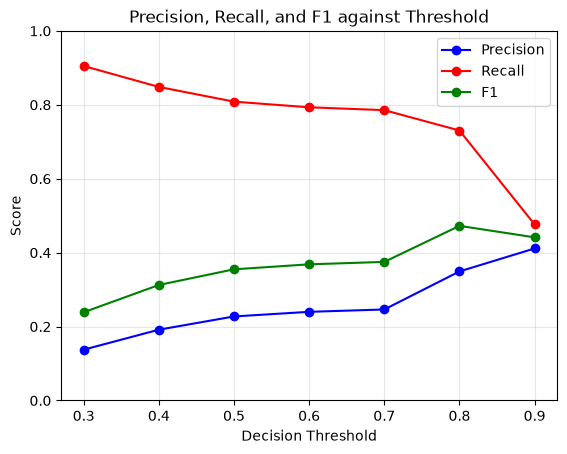

In [50]:
#attempting different thresholds
from sklearn.metrics import f1_score
stats_by_threshold = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    cur_preds = (probabilities >= threshold).astype(int)
    cur_precision = precision_score(y_test, cur_preds, zero_division=0)
    cur_recall = recall_score(y_test, cur_preds, zero_division=0)
    cur_f1 = f1_score(y_test, cur_preds, zero_division=0)

    stats = {
        "threshold": threshold,
        "alerts": cur_preds.sum(),
        "predictions": cur_preds,
        "precision": cur_precision,
        "recall": cur_recall,
        "f1": cur_f1
    }
    stats_by_threshold.append(stats)

stats_df = pd.DataFrame(stats_by_threshold)
plt.figure()
plt.plot(
    stats_df["threshold"], stats_df["precision"], marker="o", color="blue", label="Precision"
)
plt.plot(
    stats_df["threshold"], stats_df["recall"], marker="o", color="red", label="Recall" 
)
plt.plot(
    stats_df["threshold"], stats_df["f1"], marker="o", color="green", label="F1"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall, and F1 against Threshold")
plt.xticks(stats_df["threshold"])
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [51]:
print(stats_df.head(7))

   threshold  alerts                                        predictions  \
0        0.3    4296  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
1        0.4    2892  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
2        0.5    2322  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
3        0.6    2159  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
4        0.7    2083  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
5        0.8    1366  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
6        0.9     756  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   

   precision    recall        f1  
0   0.137570  0.905054  0.238836  
1   0.191563  0.848392  0.312553  
2   0.227390  0.808576  0.354958  
3   0.239926  0.793262  0.368421  
4   0.246279  0.785605  0.375000  
5   0.349195  0.730475  0.472511  
6   0.411376  0.476263  0.441448  


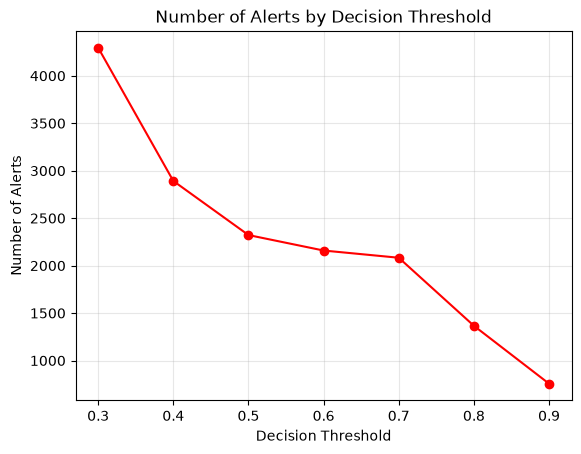

In [52]:
#plotting alerts to track relationship with changes in threshold

plt.figure()
plt.plot(
    stats_df["threshold"], stats_df["alerts"], marker="o", color="red"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Number of Alerts")
plt.title("Number of Alerts by Decision Threshold")
plt.xticks(stats_df["threshold"])
plt.grid(True, alpha=0.3)
plt.show()

/tmp/ipykernel_1854/3305018023.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


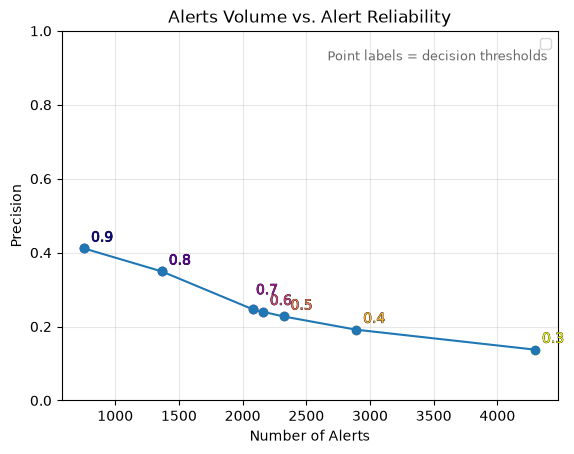

In [53]:
#plotting alerts against precision
import matplotlib.patheffects as pe
plt.figure()
plt.plot(
    stats_df["alerts"], stats_df["precision"], marker="o"
)

colors = plt.cm.plasma_r(np.linspace(0, 1, len(stats_df)))
for (i, row), color in zip(stats_df.iterrows(), colors):
    plt.scatter(row["alerts"], row["precision"], color=color)
    plt.annotate(
        f'{row["threshold"]:.1f}',
        (row["alerts"], row["precision"]),
        xytext=(2, 11) if row["threshold"] == 0.7 else (5, 5),
        textcoords="offset points",
        color=color,
        path_effects=[pe.withStroke(linewidth=0.5, foreground="black")]
    )

plt.xlabel("Number of Alerts")
plt.ylabel("Precision")
plt.title("Alerts Volume vs. Alert Reliability")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.text(0.98, 0.95, "Point labels = decision thresholds", transform=plt.gca().transAxes, ha="right", 
         va="top", fontsize=9, color="dimgray")
plt.legend()

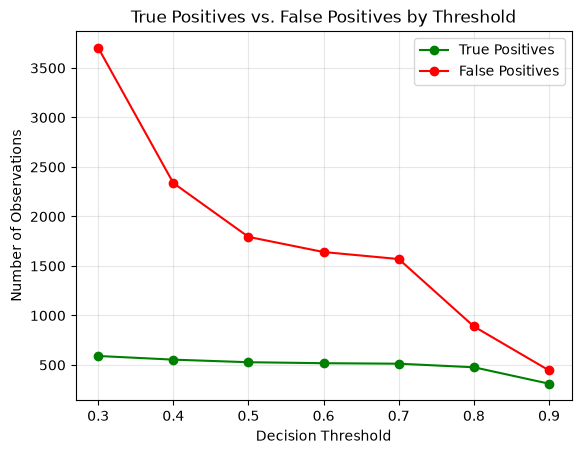

In [54]:
for stats in stats_by_threshold:
    tn, fp, fn, tp = confusion_matrix(y_test, stats["predictions"], labels=[0,1]).ravel()

    stats["true_positives"] = tp
    stats["false_positives"] = fp
    stats["false_negatives"] = fn
    stats["true_negatives"] = tn

stats_df = pd.DataFrame(stats_by_threshold)

plt.figure()
plt.plot(stats_df["threshold"], stats_df["true_positives"], marker="o", color="green", label="True Positives")
plt.plot(stats_df["threshold"], stats_df["false_positives"], marker="o", color="red", label="False Positives")
plt.xlabel("Decision Threshold")
plt.ylabel("Number of Observations")
plt.title("True Positives vs. False Positives by Threshold")
plt.xticks(stats_df["threshold"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()